# Lecture 12: Grover's search in Qiskit
ECSE 4969/6969 Quantum Information Processing, Fall 2026

Run the cells **in order**, top to bottom. Click a cell, then press the play button at its left (or Shift+Enter).

This is the same example as on the slides: **four inputs (two qubits), with the input a = 11 marked**. Cells 1 and 2 are the setup from Lecture 10. Cells 3 and 5 are shown in class; run the whole notebook after class. Cell 6 is optional.

## Cell 1. Install Qiskit into this session
Run this cell whenever you connect to a new Colab runtime. Saving your notebook does not save the installed packages. It takes about a minute.

In [1]:
!pip install -q qiskit qiskit-aer pylatexenc


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Cell 2. Check that it works
This should print a version number (a different number from the one in class is fine).

In [2]:
import qiskit
print(qiskit.__version__)
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

2.6.1


## Cell 3. Build the Grover circuit
This is the slide example: prepare the two argument qubits, mark |11> with CZ, and amplify with the fixed D block.
D = 2|all_2><all_2| - I. Its H-Z-CZ-H circuit equals D exactly, so the final state is +|11>. The CZ inside D is not another oracle call.
Compare each stage with the slide circuit before running.


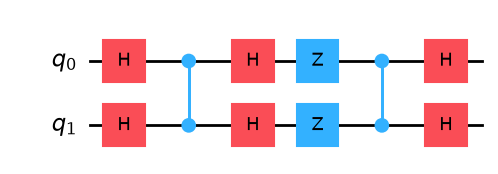

In [3]:
grover = QuantumCircuit(2)  # starts in |00>
grover.h([0, 1])            # Prepare
grover.cz(0, 1)             # Oracle: marks |11>
# Fixed amplification D = 2|all><all| - I
grover.h([0, 1])
grover.z([0, 1])
grover.cz(0, 1)             # Part of D, not another oracle call
grover.h([0, 1])
grover.draw("mpl")


## Cell 4 (after class). The state after each stage
This cell calculates the four amplitudes after preparation, after the oracle call, and after D, as in Lecture 10's cell 4. No measurement happens: this is a simulation, not a measurement. The simulator calculates the amplitudes from the known gates, which a measurement on hardware cannot return in one run. It prints only the real parts, rounded to three decimals, because every amplitude here is real (printing the state directly would show rounding errors such as -2.4e-17 in place of 0). **Predict each line before you run it.**

In [4]:
stages = QuantumCircuit(2)
stages.h([0, 1])
print("prepared:", Statevector.from_instruction(stages).data.real.round(3) + 0.0)
stages.cz(0, 1)
print("marked:  ", Statevector.from_instruction(stages).data.real.round(3) + 0.0)
# Same fixed D block as cell 3
stages.h([0, 1])
stages.z([0, 1])
stages.cz(0, 1)
stages.h([0, 1])
print("after D: ", Statevector.from_instruction(stages).data.real.round(3) + 0.0)


prepared: [0.5 0.5 0.5 0.5]
marked:   [ 0.5  0.5  0.5 -0.5]
after D:  [0. 0. 0. 1.]


The last line is +|11⟩: the marked input with certainty. This notebook implements D exactly. The textbook uses U_B = -D, whose state differs by an overall sign but gives the same probabilities. Qiskit numbers the top wire q0 and lists the four amplitudes for the labels q1q0 = 00, 01, 10, 11 (the order BA in Lecture 10's names). The target 11 looks the same in either order, but the order must be tracked for other targets.

## Cell 5. Run it and count
`measure_all(inplace=False)` makes a copy of the circuit with a measurement on every qubit, so `grover` itself is unchanged and the cell can be rerun safely. Each of the 1,024 shots starts at |00⟩, runs the complete circuit, and measures both qubits once. **Predict the counts for 1,024 runs before you run this cell.**

{'11': 1024}


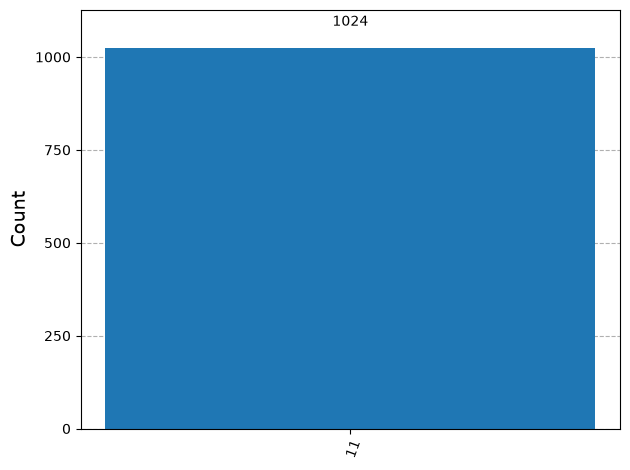

In [5]:
measured = grover.measure_all(inplace=False)
sim = AerSimulator()
job = sim.run(transpile(measured, sim), shots=1024)
counts = job.result().get_counts()
print(counts)
plot_histogram(counts)

## Cell 6 (optional). Mark a different input
To mark the input with A = 0 and B = 1 (|01⟩ in our AB order), put an X on qubit 0 (A) before and after the CZ. The CZ then flips the sign of exactly that input. D is unchanged.

Before you run it: Qiskit prints labels in the order BA, so which string should appear?

In [6]:
g2 = QuantumCircuit(2)
g2.h([0, 1])
g2.x(0); g2.cz(0, 1); g2.x(0)  # Oracle: A=0, B=1
# The same D block; only the oracle changed
g2.h([0, 1])
g2.z([0, 1])
g2.cz(0, 1)
g2.h([0, 1])
g2.measure_all()
print(sim.run(transpile(g2, sim), shots=1024).result().get_counts())


{'10': 1024}


Every run gives `10`: B = 1, A = 0 in Qiskit's BA order, which is |01⟩ in ours.